# Data Audit: Power System Load Data

Before any modelling, this notebook checks the raw data for quality problems and explores how `Load_Type` behaves.
Its findings drive the cleaning and features in `feature_engineering_modeling.ipynb`.

**Summary of findings**
| Issue | Size | Handling |
|---|---|---|
| Missing values | 1–4.5% per column | median imputation inside the model pipeline |
| Power factor outside 0–100% | 3,226 lagging + 2,685 leading | set to missing |
| Corrupted readings with extra decimals (e.g. `8.753692…`) | 3–10% per sensor column | set to missing |
| NSM inconsistent with the timestamp | 3,414 rows | not used; recomputed from the timestamp |
| Midnight rows dated with the day they close | 365 rows | moved +1 day |
| Duplicated timestamp | 1 (`31-12-2018 20:00`) | keep the copy with fewer issues |
| Class imbalance | Light 51% / Medium 28% / Maximum 21% | macro-averaged metrics |

## 1. Load the data

In [1]:
# Import libraries
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from preprocessing import has_extra_decimals, load_clean_timeline

sns.set_theme(style="whitegrid")

In [2]:
# Load the dataset

data_path = PROJECT_ROOT / "data" / "raw" / "load_data.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (35041, 9)


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


In [3]:
# Understanding the Dataset Structure

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35041 entries, 0 to 35040
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Date_Time                             35041 non-null  str    
 1   Usage_kWh                             33482 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  34165 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  33885 non-null  float64
 4   CO2(tCO2)                             34586 non-null  float64
 5   Lagging_Current_Power_Factor          34691 non-null  float64
 6   Leading_Current_Power_Factor          33570 non-null  float64
 7   NSM                                   34586 non-null  float64
 8   Load_Type                             35041 non-null  str    
dtypes: float64(7), str(2)
memory usage: 2.4 MB


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date_Time,35041,35040,31-12-2018 20:00,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Usage_kWh,33482.0,NaN,NaN,NaN,30.873061,41.415015,0.0,3.31,5.29,53.56,435.019069
Lagging_Current_Reactive.Power_kVarh,34165.0,NaN,NaN,NaN,14.704573,20.342721,0.0,2.34,5.18,23.51,262.630718
Leading_Current_Reactive_Power_kVarh,33885.0,NaN,NaN,NaN,4.386097,9.090181,0.0,0.0,0.0,2.298558,78.809
CO2(tCO2),34586.0,NaN,NaN,NaN,0.012947,0.019726,0.0,0.0,0.0,0.02,0.188166
Lagging_Current_Power_Factor,34691.0,NaN,NaN,NaN,90.740871,39.745395,0.0,66.295,90.08,100.0,299.996814
Leading_Current_Power_Factor,33570.0,NaN,NaN,NaN,94.926552,49.826872,0.0,99.8,100.0,100.0,299.969494
NSM,34586.0,NaN,NaN,NaN,48013.664032,34046.492333,0.0,22500.0,45000.0,68400.0,248821.810465
Load_Type,35041,3,Light_Load,18073,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Missing values and duplicates

In [5]:
# Missing values

missing_values = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percentage": (df.isnull().mean() * 100).round(2)
})

missing_values

,Missing,Percentage
Date_Time,0,0.00
Usage_kWh,1559,4.45
Lagging_Current_Reactive.Power_kVarh,876,2.50
Leading_Current_Reactive_Power_kVarh,1156,3.30
CO2(tCO2),455,1.30
Lagging_Current_Power_Factor,350,1.00
Leading_Current_Power_Factor,1471,4.20
NSM,455,1.30
Load_Type,0,0.00


In [6]:
# Finding Duplicate records

print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate timestamps:",
    df["Date_Time"].duplicated().sum()
)

Duplicate rows: 0
Duplicate timestamps: 1


In [7]:
# Inspecting the duplicate timestamp

duplicate_records = df[
    df["Date_Time"].duplicated(keep=False)
]

duplicate_records.T

,35023,35040
Date_Time,31-12-2018 20:00,31-12-2018 20:00
Usage_kWh,4.14,NaN
Lagging_Current_Reactive.Power_kVarh,0.0,0.0
Leading_Current_Reactive_Power_kVarh,20.09,20.1
CO2(tCO2),0.0,0.0
Lagging_Current_Power_Factor,100.0,217.27347
Leading_Current_Power_Factor,20.18,20.19
NSM,72000.0,72000.0
Load_Type,Light_Load,Light_Load


The duplicated timestamp `31-12-2018 20:00` has one copy with a missing `Usage_kWh` and an impossible power factor (217%). The other copy is clean, so that one is kept.

## 3. Impossible power factors

In [8]:
power_factor_cols = [
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor"
]

for col in power_factor_cols:
    invalid = df[
        (df[col] < 0) | (df[col] > 100)
    ]

    print(f"{col}: {len(invalid)} invalid values")

Lagging_Current_Power_Factor: 3226 invalid values
Leading_Current_Power_Factor: 2685 invalid values


In [9]:
power_factor_cols = [
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor"
]

df[power_factor_cols].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
Lagging_Current_Power_Factor,34691.0,90.740871,39.745395,0.0,43.70,66.295,90.08,100.0,178.941041,263.065579,299.996814
Leading_Current_Power_Factor,33570.0,94.926552,49.826872,0.0,15.73,99.800,100.00,100.0,207.305931,282.109799,299.969494


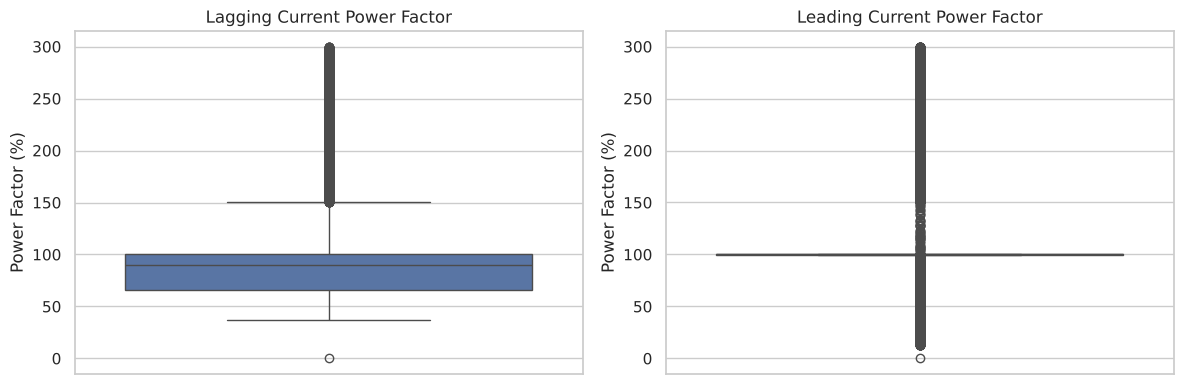

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, power_factor_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col.replace("_", " "))
    ax.set_ylabel("Power Factor (%)")

plt.tight_layout()
plt.show()

In [11]:
temp = df.copy()

temp["Date_Time"] = pd.to_datetime(
    temp["Date_Time"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

temp["Month"] = temp["Date_Time"].dt.to_period("M")

for col in power_factor_cols:
    invalid = (temp[col] < 0) | (temp[col] > 100)

    monthly_invalid = (
        invalid.groupby(temp["Month"])
        .agg(["sum", "mean"])
    )

    monthly_invalid["mean"] *= 100

    print(f"\n{col}")
    display(monthly_invalid.round(2))


Lagging_Current_Power_Factor


,sum,mean
Month,,
2018-01,305,10.25
2018-02,266,9.90
2018-03,276,9.27
2018-04,282,9.79
2018-05,275,9.24
2018-06,241,8.37
2018-07,255,8.57
2018-08,255,8.57
2018-09,247,8.58



Leading_Current_Power_Factor


,sum,mean
Month,,
2018-01,228,7.66
2018-02,203,7.55
2018-03,241,8.10
2018-04,215,7.47
2018-05,238,8.00
2018-06,222,7.71
2018-07,243,8.17
2018-08,221,7.43
2018-09,190,6.60


In [12]:
# Checking whether the invalid values overlap


lagging_invalid = (
    (df["Lagging_Current_Power_Factor"] < 0) |
    (df["Lagging_Current_Power_Factor"] > 100)
)

leading_invalid = (
    (df["Leading_Current_Power_Factor"] < 0) |
    (df["Leading_Current_Power_Factor"] > 100)
)

both_invalid = lagging_invalid & leading_invalid
any_invalid = lagging_invalid | leading_invalid

print("Invalid lagging PF:", lagging_invalid.sum())
print("Invalid leading PF:", leading_invalid.sum())
print("Both invalid:", both_invalid.sum())
print("At least one invalid:", any_invalid.sum())
print(
    "Percentage of affected rows:",
    round(any_invalid.mean() * 100, 2)
)

Invalid lagging PF: 3226
Invalid leading PF: 2685
Both invalid: 255
At least one invalid: 5656
Percentage of affected rows: 16.14


Power factors above 100% occur in every month at a similar rate (8–10%) and affect 16% of rows. That looks like random corruption, not a sensor fault in one period.

## 4. Corrupted readings with extra decimal places
The power-factor problem is part of a wider pattern. Genuine readings in this file have **at most two decimals** (`3.24`, `73.21`), but about 10% of values in every sensor column look like `8.753692425450835`.

In [13]:
sensor_cols = [
    "Usage_kWh", "Lagging_Current_Reactive.Power_kVarh", "Leading_Current_Reactive_Power_kVarh",
    "CO2(tCO2)", "Lagging_Current_Power_Factor", "Leading_Current_Power_Factor",
]
extra_decimals = pd.DataFrame({c: has_extra_decimals(df[c]) for c in sensor_cols})
display(pd.DataFrame({
    "Extra-decimal values": extra_decimals.sum(),
    "Percentage": (extra_decimals.mean() * 100).round(2),
}))

for col in ["Lagging_Current_Power_Factor", "Leading_Current_Power_Factor"]:
    over_100 = df[col] > 100
    print(f"{col}: {over_100.sum()} values > 100, of which {(over_100 & extra_decimals[col]).sum()} have extra decimals")

,Extra-decimal values,Percentage
Usage_kWh,3358,9.58
Lagging_Current_Reactive.Power_kVarh,2710,7.73
Leading_Current_Reactive_Power_kVarh,1137,3.24
CO2(tCO2),1369,3.91
Lagging_Current_Power_Factor,3461,9.88
Leading_Current_Power_Factor,3346,9.55


Lagging_Current_Power_Factor: 3226 values > 100, of which 3226 have extra decimals
Leading_Current_Power_Factor: 2685 values > 100, of which 2685 have extra decimals


Median of Usage / mean(neighbours):
  extra-decimal values: 2.02
  normal values       : 0.98


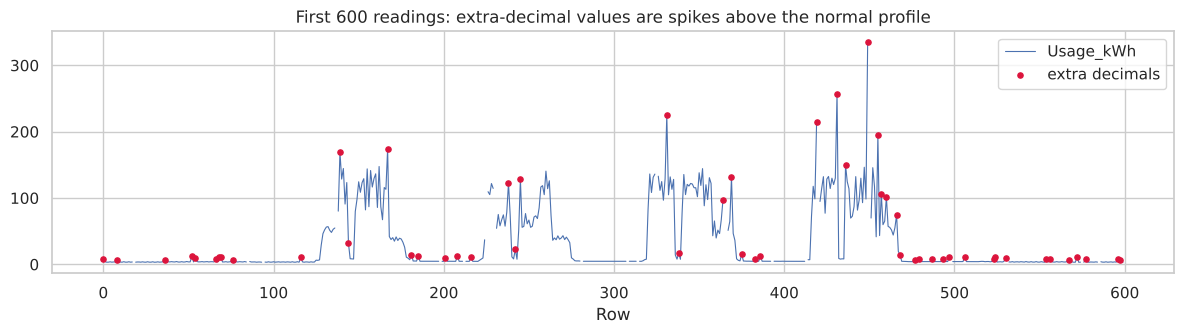

In [14]:
# Are extra-decimal values really wrong? Compare each Usage value with its two neighbours
usage = df["Usage_kWh"]
neighbour_ratio = usage / ((usage.shift(1) + usage.shift(-1)) / 2)
print("Median of Usage / mean(neighbours):")
print("  extra-decimal values:", round(neighbour_ratio[extra_decimals["Usage_kWh"]].median(), 2))
print("  normal values       :", round(neighbour_ratio[~extra_decimals["Usage_kWh"] & usage.notna()].median(), 2))

window = df.iloc[:600]
flag = extra_decimals["Usage_kWh"].iloc[:600]
plt.figure(figsize=(12, 3.5))
plt.plot(window.index, window["Usage_kWh"], lw=0.8, label="Usage_kWh")
plt.scatter(window.index[flag], window["Usage_kWh"][flag], color="crimson", s=14, zorder=3, label="extra decimals")
plt.title("First 600 readings: extra-decimal values are spikes above the normal profile")
plt.xlabel("Row"); plt.legend(); plt.tight_layout(); plt.show()

* **Every** power factor above 100 has extra decimals.
* A `Usage_kWh` value with extra decimals is typically **~2×** its neighbouring readings, while normal values are ~1×.

So the extra-decimal values are corrupted measurements, not just more precise ones. They are set to missing in the modelling pipeline (`SensorCleaner` in `src/preprocessing.py`).

## 5. Timestamps

In [15]:
# Convert the Timestamp

df["Date_Time"] = pd.to_datetime(
    df["Date_Time"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

print("Invalid timestamps:", df["Date_Time"].isna().sum())
print("Start date:", df["Date_Time"].min())
print("End date:", df["Date_Time"].max())
print("Chronologically sorted:", df["Date_Time"].is_monotonic_increasing)

Invalid timestamps: 0
Start date: 2018-01-01 00:00:00
End date: 2018-12-31 23:45:00
Chronologically sorted: False


In [16]:
# Check sampling intervals

timestamps = df["Date_Time"].dropna().sort_values()

time_diff = timestamps.diff().dropna()

print("Most common time intervals:")
display(time_diff.value_counts().head(10))

print("Intervals greater than 15 minutes:",
      (time_diff > pd.Timedelta(minutes=15)).sum())

print("Duplicate intervals:",
      (time_diff == pd.Timedelta(0)).sum())

Most common time intervals:


Date_Time
0 days 00:15:00    35039
0 days 00:00:00        1
Name: count, dtype: int64

Intervals greater than 15 minutes: 0
Duplicate intervals: 1


In [17]:
# Find missing timestamps

expected_timestamps = pd.date_range(
    start=df["Date_Time"].min(),
    end=df["Date_Time"].max(),
    freq="15min"
)

actual_timestamps = pd.DatetimeIndex(
    df["Date_Time"].dropna().unique()
)

missing_timestamps = expected_timestamps.difference(
    actual_timestamps
)

print("Expected timestamps:", len(expected_timestamps))
print("Unique actual timestamps:", len(actual_timestamps))
print("Missing timestamps:", len(missing_timestamps))

display(missing_timestamps[:20])

Expected timestamps: 35040
Unique actual timestamps: 35040
Missing timestamps: 0


DatetimeIndex([], dtype='datetime64[us]', freq='15min')

In [18]:
# Why is the file not sorted? Look at the end of the first day
df.loc[93:97, ["Date_Time", "NSM", "Usage_kWh", "Load_Type"]]

,Date_Time,NSM,Usage_kWh,Load_Type
93,2018-01-01 23:30:00,84600.0,3.24,Light_Load
94,2018-01-01 23:45:00,85500.0,NaN,Light_Load
95,2018-01-01 00:00:00,0.0,3.42,Light_Load
96,2018-01-02 00:15:00,900.0,3.20,Light_Load
97,2018-01-02 00:30:00,1800.0,3.85,Light_Load


The reading after `2018-01-01 23:45` is stamped `2018-01-01 00:00`. It is the midnight that **closes** 1 January, written with the day's own date. This happens at every midnight (365 rows). Sorting by the raw timestamp would put each midnight reading at the *start* of its day, 24 hours too early.

In [19]:
# Check NSM consistency

expected_nsm = (
    df["Date_Time"].dt.hour * 3600
    + df["Date_Time"].dt.minute * 60
    + df["Date_Time"].dt.second
)

nsm_invalid_range = (
    (df["NSM"] < 0) |
    (df["NSM"] >= 86400)
)

nsm_mismatch = (
    df["NSM"].notna()
    & expected_nsm.notna()
    & ~np.isclose(df["NSM"], expected_nsm)
)

print("NSM outside valid range:", nsm_invalid_range.sum())
print("NSM inconsistent with timestamp:", nsm_mismatch.sum())

NSM outside valid range: 1773
NSM inconsistent with timestamp: 3414


NSM disagrees with the timestamp in 3,414 rows, and 1,773 values exceed the 86,400 seconds in a day. NSM carries no information beyond the timestamp, so it is recomputed from the corrected timestamp rather than used as given.

In [20]:
# Corrected timeline: midnight rows moved +1 day, duplicate timestamp resolved
df_sorted = load_clean_timeline(data_path)

steps = df_sorted["Date_Time"].diff().dropna()
print("Rows:", len(df_sorted))
print("Strictly increasing:", df_sorted["Date_Time"].is_monotonic_increasing)
print("All steps exactly 15 minutes:", bool((steps == pd.Timedelta(minutes=15)).all()))
print("Duplicate timestamps:", df_sorted["Date_Time"].duplicated().sum())

Rows: 35040
Strictly increasing: True
All steps exactly 15 minutes: True
Duplicate timestamps: 0


In [21]:
# Verify monthly record counts (each reading is assigned to the month in which its 15-minute interval starts)
monthly_counts = (
    df_sorted.groupby(
        (df_sorted["Date_Time"] - pd.Timedelta(minutes=15)).dt.to_period("M")
    )
    .size()
)

monthly_counts

Date_Time
2018-01    2976
2018-02    2688
2018-03    2976
2018-04    2880
2018-05    2976
2018-06    2880
2018-07    2976
2018-08    2976
2018-09    2880
2018-10    2976
2018-11    2880
2018-12    2976
Freq: M, dtype: int64

Every month has exactly 96 readings × number of days, so no data is missing from the timeline.

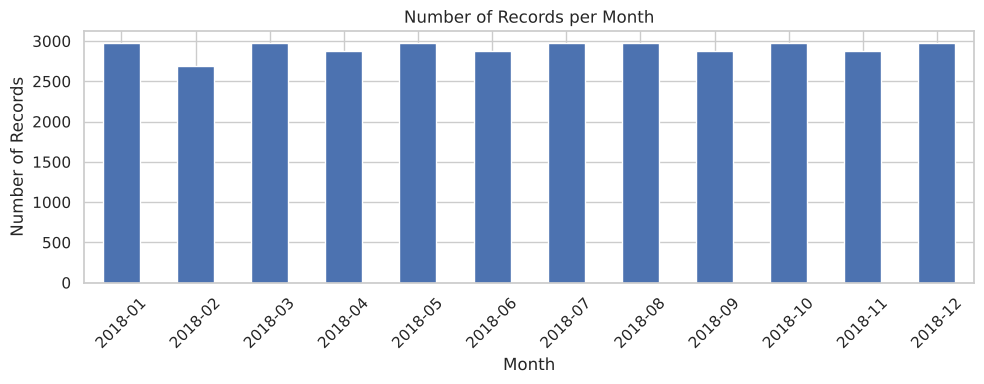

In [22]:
plt.figure(figsize=(10, 4))

monthly_counts.plot(kind="bar")

plt.title("Number of Records per Month")
plt.xlabel("Month")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Development / test split
The **last month (December 2018) is the test set** and is not looked at again in this notebook. Each 15-minute reading closes its interval, so a month runs from 00:15 on the 1st up to and including midnight at the end of the last day.

In [23]:
test_start = pd.Timestamp("2018-12-01")

train_dev = df_sorted[df_sorted["Date_Time"] <= test_start].copy()
test = df_sorted[df_sorted["Date_Time"] > test_start].copy()

print("Development records:", len(train_dev), "|", train_dev["Date_Time"].min(), "->", train_dev["Date_Time"].max())
print("Test records       :", len(test), "|", test["Date_Time"].min(), "->", test["Date_Time"].max())

assert len(train_dev) + len(test) == len(df_sorted)
assert train_dev["Date_Time"].max() < test["Date_Time"].min()

Development records: 32064 | 2018-01-01 00:15:00 -> 2018-12-01 00:00:00
Test records       : 2976 | 2018-12-01 00:15:00 -> 2019-01-01 00:00:00


## 7. Target distribution (development set)

In [24]:
# Class distribution

class_counts = train_dev["Load_Type"].value_counts()

class_percentages = (
    train_dev["Load_Type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

display(class_distribution)

,Count,Percentage
Load_Type,,
Light_Load,16328,50.92
Medium_Load,8992,28.04
Maximum_Load,6744,21.03


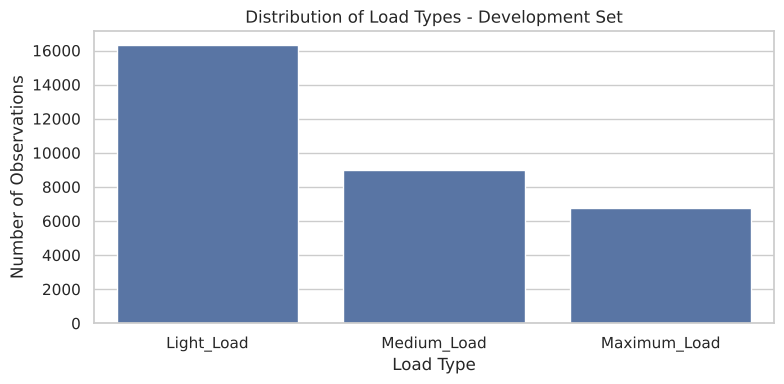

In [25]:
# Plotting the distribution

plt.figure(figsize=(8, 4))

sns.countplot(
    data=train_dev,
    x="Load_Type",
    order=["Light_Load", "Medium_Load", "Maximum_Load"]
)

plt.title("Distribution of Load Types - Development Set")
plt.xlabel("Load Type")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

The classes are imbalanced, with Light at about half the data. Accuracy alone would flatter a model that over-predicts Light, so macro-averaged precision, recall and F1 are reported as well.

In [26]:
# Electricity usage by load category

usage_summary = (
    train_dev.groupby("Load_Type")["Usage_kWh"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(usage_summary)

,count,mean,median,std,min,max
Load_Type,,,,,,
Light_Load,15631,9.99,3.35,22.37,0.00,304.71
Maximum_Load,6460,68.94,59.90,41.65,2.92,401.78
Medium_Load,8578,42.85,34.92,44.97,2.52,435.02


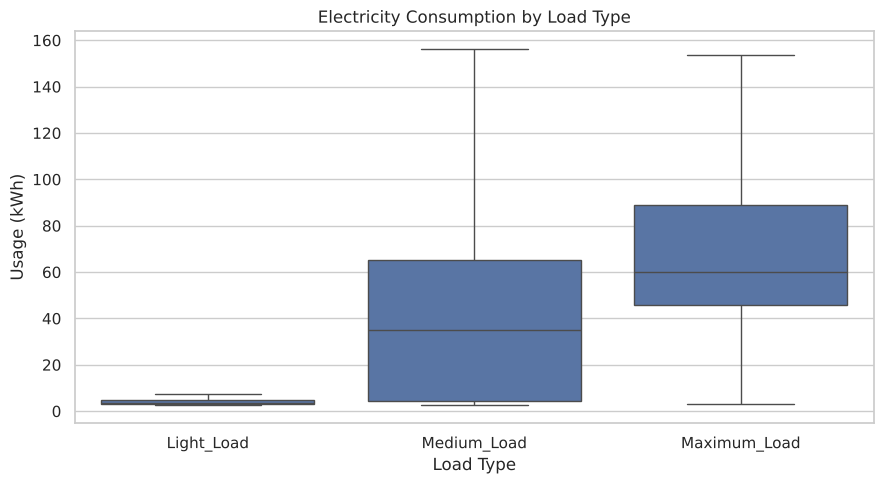

In [27]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=train_dev,
    x="Load_Type",
    y="Usage_kWh",
    order=["Light_Load", "Medium_Load", "Maximum_Load"],
    showfliers=False
)

plt.title("Electricity Consumption by Load Type")
plt.xlabel("Load Type")
plt.ylabel("Usage (kWh)")

plt.tight_layout()
plt.show()

Usage separates Light from the other two classes well, but Medium and Maximum overlap heavily. Usage alone can't tell them apart.

## 8. Load type by time of day and weekday

In [28]:
# Load category by hour of day

eda_df = train_dev.copy()

eda_df["Hour"] = eda_df["Date_Time"].dt.hour

hourly_load = pd.crosstab(
    eda_df["Hour"],
    eda_df["Load_Type"],
    normalize="index"
) * 100

display(hourly_load.head())

Load_Type,Light_Load,Maximum_Load,Medium_Load
Hour,,,
0,100.0,0.0,0.0
1,100.0,0.0,0.0
2,100.0,0.0,0.0
3,100.0,0.0,0.0
4,100.0,0.0,0.0


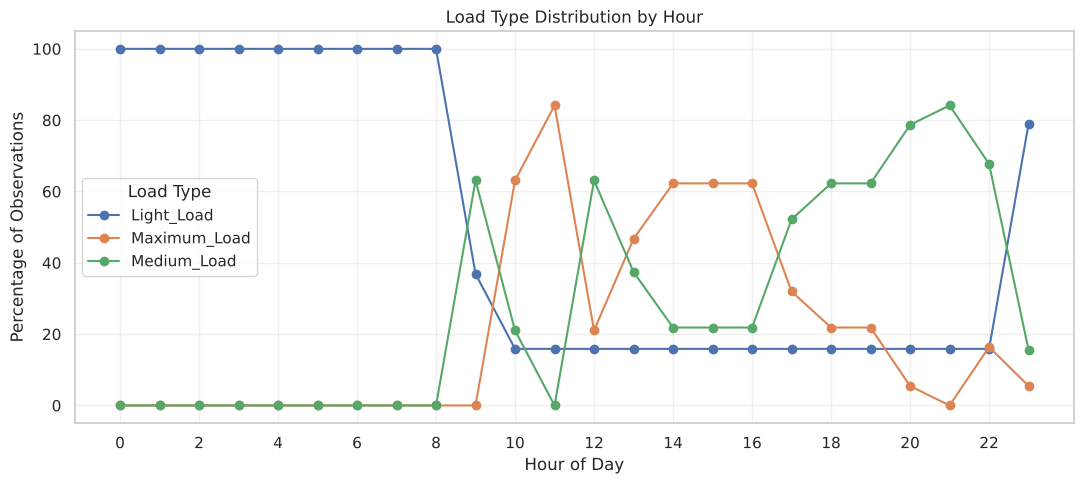

In [29]:
hourly_load.plot(
    kind="line",
    figsize=(11, 5),
    marker="o"
)

plt.title("Load Type Distribution by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Percentage of Observations")
plt.xticks(range(0, 24, 2))
plt.legend(title="Load Type")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
# Create day of week features

eda_df["Day_of_Week"] = eda_df["Date_Time"].dt.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_distribution = pd.crosstab(
    eda_df["Day_of_Week"],
    eda_df["Load_Type"],
    normalize="index"
) * 100

weekday_distribution = weekday_distribution.reindex(day_order)

display(weekday_distribution.round(2))

Load_Type,Light_Load,Maximum_Load,Medium_Load
Day_of_Week,,,
Monday,44.09,23.96,31.95
Tuesday,44.10,23.96,31.94
Wednesday,45.31,23.44,31.25
Thursday,44.10,23.96,31.94
Friday,44.10,23.96,31.94
Saturday,55.33,19.14,25.53
Sunday,80.14,8.51,11.35


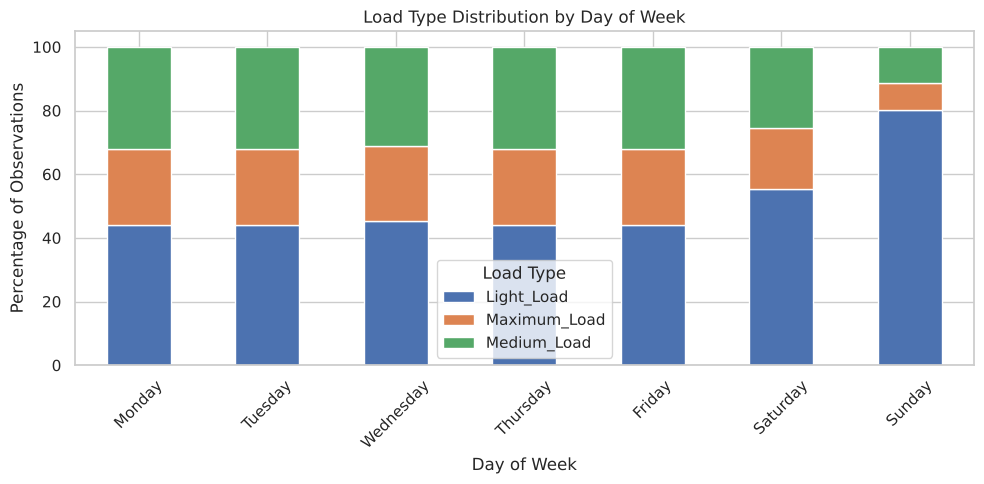

In [31]:
weekday_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Load Type Distribution by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Percentage of Observations")
plt.xticks(rotation=45)
plt.legend(title="Load Type")
plt.tight_layout()
plt.show()

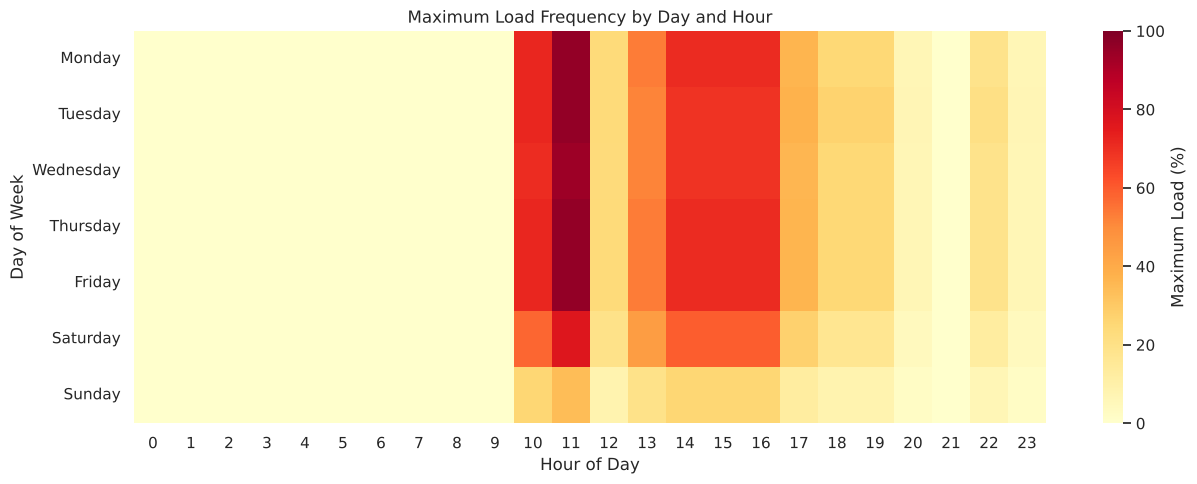

In [32]:
heatmap_data = (
    eda_df.assign(
        Is_Maximum_Load=(
            eda_df["Load_Type"] == "Maximum_Load"
        ).astype(int)
    )
    .pivot_table(
        index="Day_of_Week",
        columns="Hour",
        values="Is_Maximum_Load",
        aggfunc="mean"
    )
    .reindex(day_order)
)

plt.figure(figsize=(13, 5))

sns.heatmap(
    heatmap_data * 100,
    cmap="YlOrRd",
    annot=False,
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Maximum Load (%)"}
)

plt.title("Maximum Load Frequency by Day and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()

* 00:00–08:00 is always Light. Medium and Maximum occur only during working hours.
* Sundays are ~80% Light and Saturdays ~55%. Weekdays are nearly identical to each other.
* Maximum load is concentrated in fixed weekday time blocks, which suggests a fixed operating or tariff schedule.

## 9. Load type by month

In [33]:
# Monthly class distribution

eda_df["Month"] = eda_df["Date_Time"].dt.month

monthly_load = pd.crosstab(
    eda_df["Month"],
    eda_df["Load_Type"],
    normalize="index"
) * 100

display(monthly_load.round(2))

Load_Type,Light_Load,Maximum_Load,Medium_Load
Month,,,
1,49.18,21.78,29.04
2,60.42,16.96,22.62
3,47.31,22.58,30.11
4,47.50,22.50,30.00
5,51.08,20.97,27.96
6,51.39,20.83,27.78
7,45.43,23.39,31.18
8,56.72,18.55,24.73
9,55.28,19.17,25.56


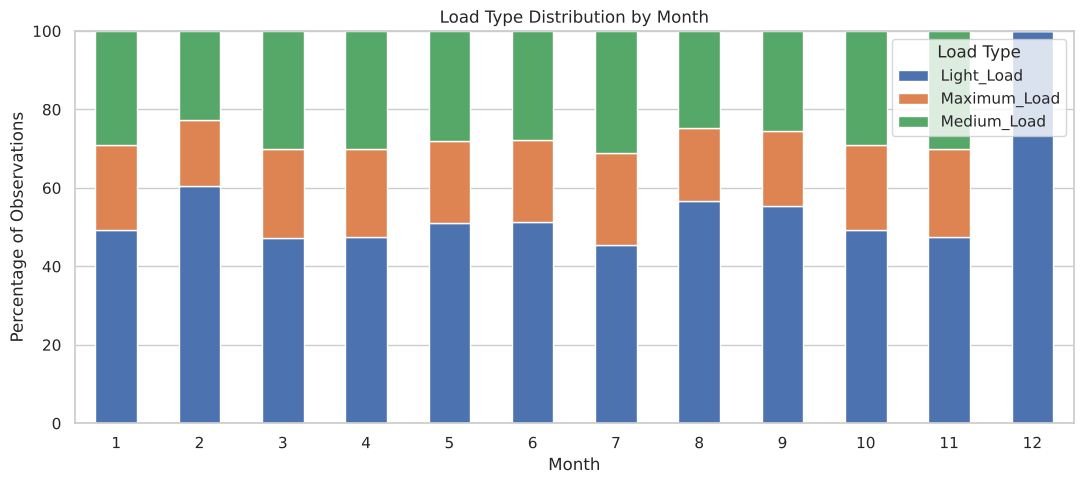

In [34]:
monthly_load.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5)
)

plt.title("Load Type Distribution by Month")
plt.xlabel("Month")
plt.ylabel("Percentage of Observations")
plt.xticks(rotation=0)
plt.legend(title="Load Type")
plt.tight_layout()
plt.show()

The class mix is fairly stable across months. Differences come mostly from the number of weekend days and holidays in each month.

## 10. How consistent is the schedule?

In [35]:
schedule_consistency = (
    eda_df.groupby(["Day_of_Week", "Hour"])["Load_Type"]
    .nunique()
    .reset_index(name="Unique_Load_Types")
)

print(
    schedule_consistency["Unique_Load_Types"].value_counts()
)

display(
    schedule_consistency[
        schedule_consistency["Unique_Load_Types"] > 1
    ].head(20)
)

Unique_Load_Types
3    84
1    63
2    21
Name: count, dtype: int64


,Day_of_Week,Hour,Unique_Load_Types
9,Friday,9,2
10,Friday,10,3
11,Friday,11,2
12,Friday,12,3
13,Friday,13,3
14,Friday,14,3
15,Friday,15,3
16,Friday,16,3
17,Friday,17,3
18,Friday,18,3


In [36]:
eda_df["Time_Slot"] = (
    eda_df["Date_Time"].dt.hour * 4
    + eda_df["Date_Time"].dt.minute // 15
)

slot_consistency = (
    eda_df.groupby(["Day_of_Week", "Time_Slot"])["Load_Type"]
    .nunique()
)

print("Number of load categories per weekday/time slot:")
print(slot_consistency.value_counts().sort_index())

print("\nPercentage of slots with one category:")
print(round((slot_consistency == 1).mean() * 100, 2))

Number of load categories per weekday/time slot:
Load_Type
1    280
2    168
3    224
Name: count, dtype: int64

Percentage of slots with one category:
41.67


In [37]:
# Calculate the dominant class consistency


slot_counts = (
    eda_df.groupby(
        ["Day_of_Week", "Time_Slot", "Load_Type"]
    )
    .size()
    .unstack(fill_value=0)
)

dominant_share = (
    slot_counts.max(axis=1)
    / slot_counts.sum(axis=1)
)

print("Mean dominant class percentage:",
      round(dominant_share.mean() * 100, 2))

print("Minimum dominant class percentage:",
      round(dominant_share.min() * 100, 2))

print("Slots with at least 90% agreement:",
      (dominant_share >= 0.90).sum())

print("Total weekday/time slots:", len(dominant_share))

Mean dominant class percentage: 86.44
Minimum dominant class percentage: 59.57
Slots with at least 90% agreement: 400
Total weekday/time slots: 672


For a given weekday and 15-minute slot, the most frequent load type accounts for **86% of readings on average**. Most of the target is explained by the weekly schedule. The remaining disagreement comes partly from schedule changes between months, which `feature_engineering_modeling.ipynb` investigates.

## 11. Relationships between features

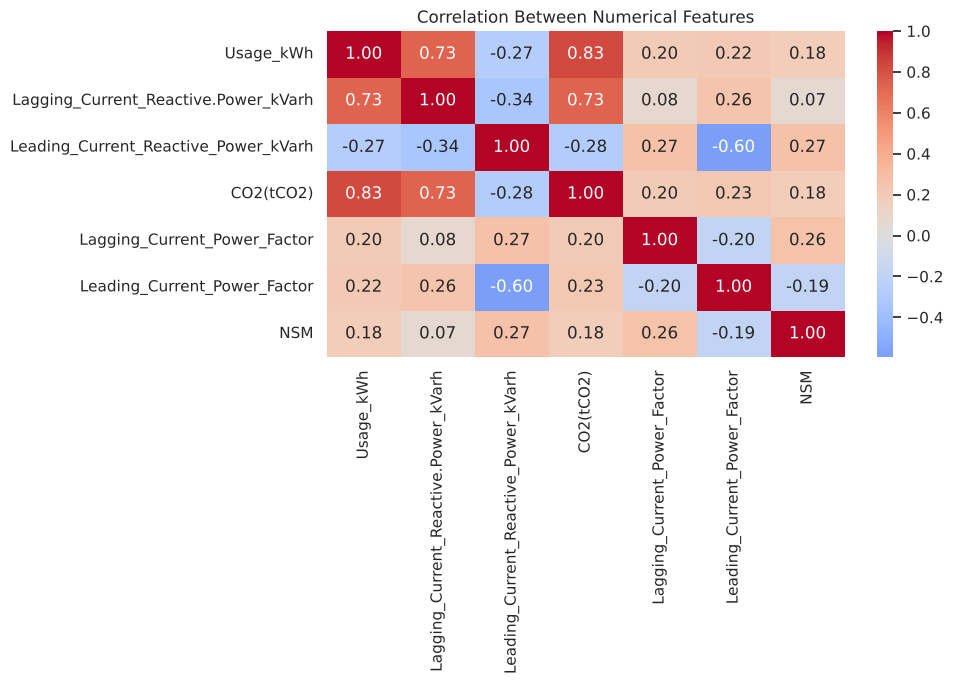

In [38]:
# Correlation matrix

numeric_cols = train_dev.select_dtypes(
    include="number"
).columns

correlation_matrix = train_dev[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

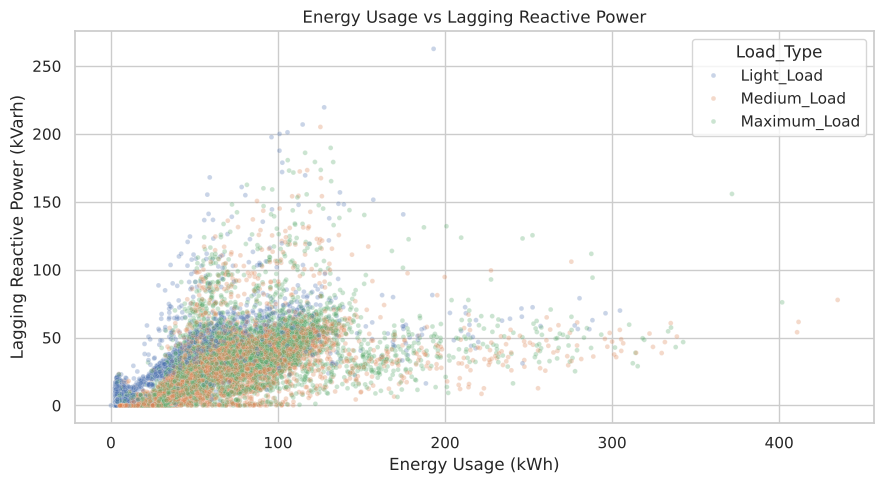

In [39]:
# Examine usage and reactive power

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=train_dev,
    x="Usage_kWh",
    y="Lagging_Current_Reactive.Power_kVarh",
    hue="Load_Type",
    alpha=0.3,
    s=12
)

plt.title("Energy Usage vs Lagging Reactive Power")
plt.xlabel("Energy Usage (kWh)")
plt.ylabel("Lagging Reactive Power (kVarh)")
plt.tight_layout()
plt.show()

* `Usage_kWh`, lagging reactive power and CO2 are strongly correlated. CO2 is effectively proportional to energy used.
* Usage separates Light load well, while Medium and Maximum overlap. The time-based schedule features will matter more than the electrical readings.